# LLM-directed bike-share evidence review
**AI Foundations (Edward Hickman) · Udacity · Project 7, revised**

Urban bike-share analysts need inspectable evidence, not automatic dispatch.
This revision integrates Project 2's statistical reasoning, Project 3's unchanged
fixed rental model, and **corrected Project 6's real MiniMax/LangGraph agent**.
The prior rule-only agentic contribution is superseded, not relabeled.

AI assisted with preparation, code, tests and drafting. Edward must review,
understand and personalize the work under course policy. No claim of independent
authorship, classroom acceptance, production deployment or completed defense.

In [1]:
from pathlib import Path
import hashlib, inspect, json, platform
from importlib.metadata import version
import pandas as pd
from IPython.display import Code, Image, display
import integrated_system
from integrated_system import ROOT, CONFIG, Request, SynthesisAgent

OUT = Path("outputs")
SAVED = OUT / "llm_runs"
versions = {"python": platform.python_version(),
            **{p: version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn",
                                      "langgraph", "langchain-openai", "langchain-core"]}}
(OUT / "runtime_versions.json").write_text(json.dumps(versions, indent=2) + "\n")
display(versions)
assert hashlib.sha256(Path("data/hour.csv").read_bytes()).hexdigest() == CONFIG["source_sha256"]
print("Pinned public source: 17,379 records, 17 columns; no raw rows sent to the provider.")

{'python': '3.11.18',
 'numpy': '2.4.6',
 'pandas': '3.1.1',
 'scipy': '1.17.1',
 'scikit-learn': '1.9.1',
 'langgraph': '1.2.24',
 'langchain-openai': '1.8.5',
 'langchain-core': '1.8.4'}

Pinned public source: 17,379 records, 17 columns; no raw rows sent to the provider.


## 1. Architecture and responsibility
The LLM interprets instructions and selects a tool or final response after each
observation. LangGraph alternates decision and execution nodes. There is no
Python-selected checklist. Dependencies enforce valid computation; after modeling,
daily association, hourly errors and demand stress are independently selectable.

Python—not model persuasion—enforces registered data, read-only tools, quality
holds, seven executions, sixteen model turns, one tool per turn and no repeats.
Memory contains messages, observations, counters and temporary data for one run.
Raw source records stay local; instructions and aggregate tool results go to MiniMax.
Public reasons are brief justifications, not hidden chain-of-thought.

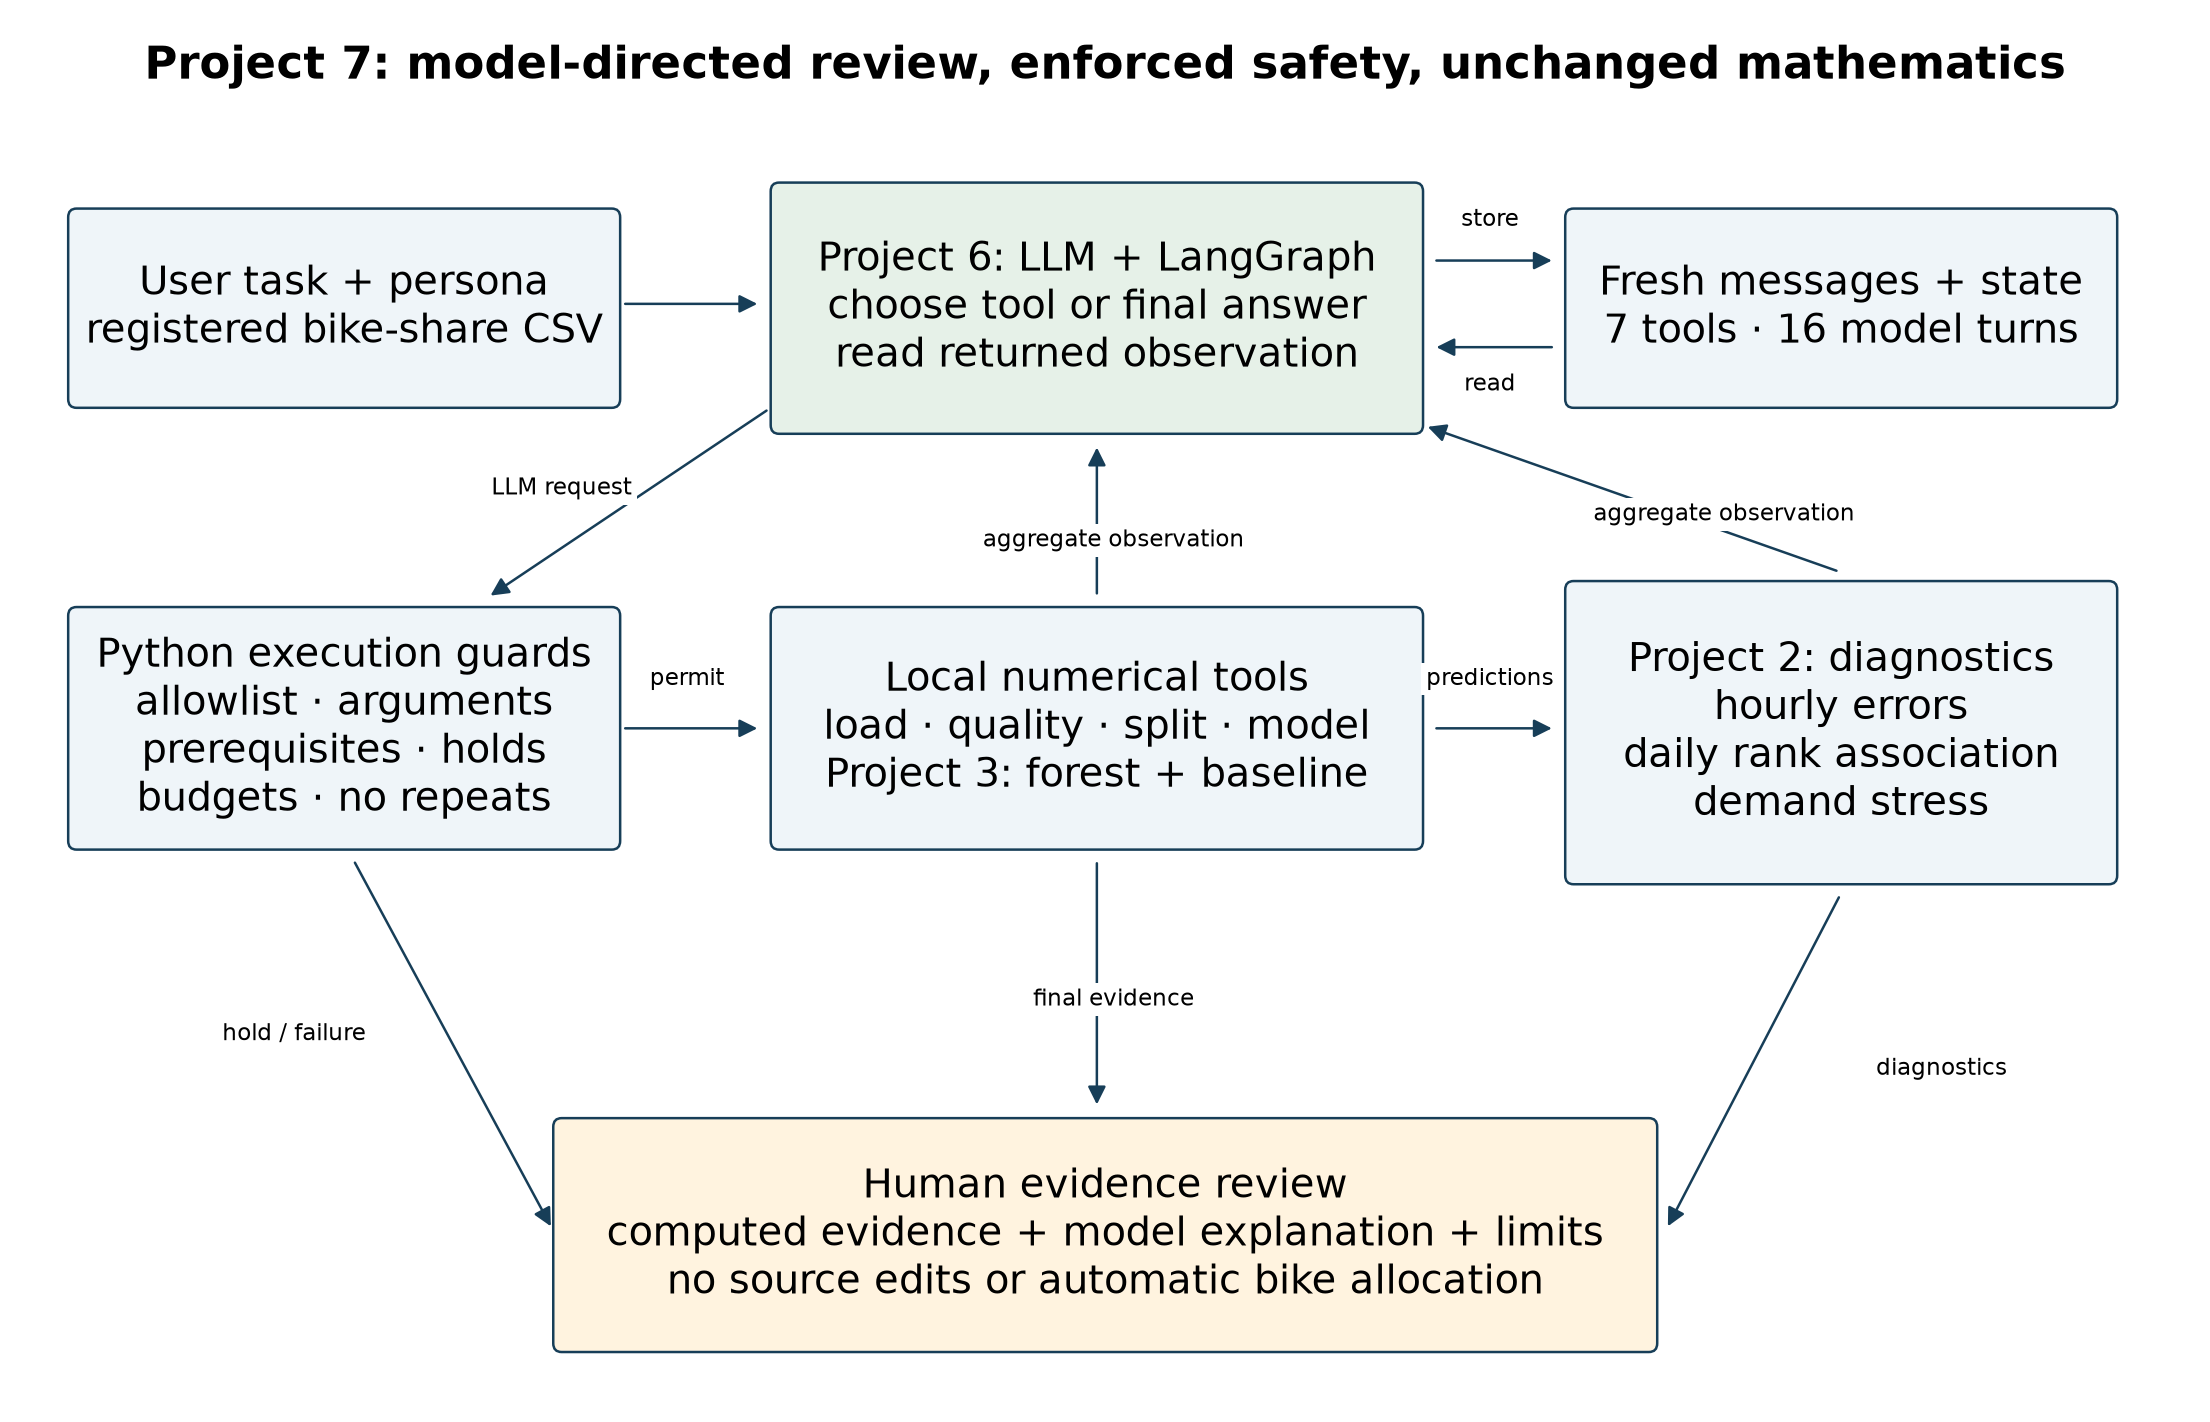

"""LLM-directed bike-share evidence review with deterministic numerical tools."""
from dataclasses import dataclass, field
import hashlib
import io
import json
import os
from pathlib import Path
from typing import Annotated, TypedDict

from langchain_core.messages import AIMessage, HumanMessage, SystemMessage, ToolMessage
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages

import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder


ROOT = Path(__file__).resolve().parent
CONFIG = json.loads((ROOT / "config.json").read_text())
FEATURES = CONFIG["categorical"] + CONFIG["numeric"]
REQUIRED = FEATURES + ["instant", "dteday", "casual", "registered", "cnt"]


class ToolFailure(Exception):
    pass


@dataclass(frozen=True)
class Request:
    dataset_id: str = "bike_hourly_2011_2012"
    intent: str = "retrospective_review"
    max_tool_calls: int = 7
    scope: str = "full"
    instructions: str = "Review the historical bike-share data, model and all three error diagnostics. Explain limitations."


@dataclass
class State:
    completed: list = field(default_factory=list)
    observations: dict = field(default_factory=dict)
    trace: list = field(default_factory=list)
    calls: int = 0
    frame: pd.DataFrame | None = None
    development: pd.DataFrame | None = None
    test: pd.DataFrame | None = None
    predictions: pd.DataFrame | None = None
    daily: pd.DataFrame | None = None
    hourly: pd.DataFrame | None = None
    tool_failed: bool = False

    def log(self, action, reason, outcome):
        self.trace.append({"sequence": len(self.trace) + 1, "action": action,
                           "reason": reason, "outcome": outcome})


class EvidenceTools:
    def __init__(self, fixture=None, fail_tool=None):
        self.fixture = fixture
        self.fail_tool = fail_tool

    def dispatch(self, name, state):
        tools = {"load": self.load, "quality": self.quality, "split": self.split,
                 "model": self.model, "daily_association": self.daily_association,
                 "hourly_errors": self.hourly_errors, "demand_stress": self.demand_stress}
        if name not in tools or name == self.fail_tool:
            raise ToolFailure("Unknown or deliberately failed evaluation tool")
        return tools[name](state)

    def load(self, state):
        if self.fixture is None:
            path = ROOT / CONFIG["relative_path"]
            if path.stat().st_size > CONFIG["max_bytes"]:
                raise ToolFailure("Registered source exceeds byte limit")
            raw = path.read_bytes()
            if hashlib.sha256(raw).hexdigest() != CONFIG["source_sha256"]:
                raise ToolFailure("Registered source fingerprint mismatch")
            frame = pd.read_csv(io.BytesIO(raw))
        else:
            frame = self.fixture.copy(deep=True)
        if not 0 < len(frame) <= CONFIG["max_rows"] or not 0 < len(frame.columns) <= 20:
            raise ToolFailure("Invalid input dimensions")
        if not frame.columns.is_unique:
            raise ToolFailure("Repeated column names")
        state.frame = frame
        return {"rows": len(frame), "columns": len(frame.columns),
                "source": "declared test fixture" if self.fixture is not None else "pinned historical CSV"}

    def quality(self, state):
        frame = state.frame
        missing = sorted(set(REQUIRED) - set(frame.columns))
        extra = len(set(frame.columns) - set(REQUIRED))
        issues = []
        if missing:
            issues.append("required_columns_missing")
        if extra:
            issues.append("unrecognized_columns")
        if missing or extra:
          

In [2]:
display(Image(filename=str(OUT / "architecture_diagram.png")))
display(Code(inspect.getsource(integrated_system), language="python"))

## 2. Saved real-provider suite: provenance before interpretation
These are genuine saved provider responses, not scripted test doubles.
The evaluator records thirteen designed development cases, including one invalid
structured request blocked without any provider call. They are not a held-out
reliability benchmark. Earlier live attempts are retained separately.

In [3]:
manifest = json.loads((SAVED / "run_manifest.json").read_text())
assert manifest["implementation_sha256"] == hashlib.sha256(Path("integrated_system.py").read_bytes()).hexdigest()
assert manifest["evaluator_sha256"] == hashlib.sha256(Path("evaluate_system.py").read_bytes()).hexdigest()
result = json.loads((SAVED / "original.json").read_text())
scenarios = pd.read_csv(SAVED / "scenario_summary.csv")
display(manifest)
display(scenarios[["scenario", "status", "model_turns", "tool_calls"]])
print("Actual full-run tool sequence:", " → ".join(result["completed_tools"]))
assert result["status"] == "completed" and result["full_pipeline_coverage"]

{'started_at_utc': '2026-11-20T03:58:58.840244+00:00',
 'python': '3.11.18',
 'implementation_sha256': 'c30f5b2f1ef9e49b0262903b3e0226a1266c4d75853de4919a4a1fd9fd5b8d07',
 'evaluator_sha256': '0b2e41ab5ecc3d52609317d462fffe33c2247d28ed63728790358236e1e926b4',
 'config': {'dataset_id': 'bike_hourly_2011_2012',
  'relative_path': 'data/hour.csv',
  'source_sha256': 'e03de4ee4ef4dc376ac6e04bf829673c6269e8eba5c60fa121640fa2f829504f',
  'max_bytes': 2000000,
  'max_rows': 20000,
  'max_tool_calls': 7,
  'max_model_turns': 16,
  'model': 'MiniMax-M3',
  'provider_timeout_seconds': 60,
  'categorical': ['season',
   'yr',
   'mnth',
   'hr',
   'holiday',
   'weekday',
   'workingday',
   'weathersit'],
  'numeric': ['temp', 'atemp', 'hum', 'windspeed'],
  'allowed_categories': {'season': [1, 2, 3, 4],
   'yr': [0, 1],
   'mnth': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12],
   'hr': [0,
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12,
    13,
    14,
    15,


,scenario,status,model_turns,tool_calls
0,original,completed,8,7
1,missing_value,held,3,2
2,duplicate_key,held,3,2
3,invalid_hour,held,3,2
4,unknown_weather,held,3,2
5,nonfinite,held,3,2
6,missing_column,held,3,2
7,quality_only,completed,3,2
8,hourly_only,completed,6,5
9,allocation_request,completed,1,0


Actual full-run tool sequence: load → quality → split → model → hourly_errors → demand_stress → daily_association


## 3. Inspect the reasoning/action/observation loop
Every requested action below came from an actual AIMessage. Every tool observation
was returned in a ToolMessage before the next LLM decision. Final prose is separate
from authoritative computed observations. This does not expose private model reasoning.
Read `outputs/explanation_audit.json`: current prose still contains unsupported
interpretations, including an untested error mechanism and an accuracy judgment
without an operational tolerance. The stored LLM narrative is evidence to critique,
not a model answer to memorize.

In [4]:
for message in result["messages"]:
    if message["role"] == "ai":
        print("\nMODEL:", message["content"])
        for call in message["tool_calls"]:
            print("SELECTED:", call["name"], "| PUBLIC REASON:", call["args"]["reason"])
    elif message["role"] == "tool":
        print("OBSERVATION:", message["name"], message["content"])
display(pd.DataFrame(result["trace"]))


MODEL: I'll start by loading the registered dataset to establish what's available.
SELECTED: load | PUBLIC REASON: Start the full review by loading the registered historical CSV and seeing its aggregate dimensions.
OBSERVATION: load {"rows": 17379, "columns": 17, "source": "pinned historical CSV"}

MODEL: The dataset loaded: 17,379 rows and 17 columns. Now I'll run the mandatory quality gate before any partitioning.
SELECTED: quality | PUBLIC REASON: Mandatory quality check on schema, missingness, keys, ranges and consistency before any split.
OBSERVATION: quality {"issues": [], "missing_cells": 0, "duplicate_keys": 0, "invalid_category_columns": [], "scope": "Configured structural/range checks; no quality certification or automatic cleaning."}

MODEL: Quality is clear — no issues, no missing cells, no duplicate keys. Proceeding to the chronological split.
SELECTED: split | PUBLIC REASON: Create whole-date development/test partitions now that the quality gate is clear.
OBSERVATION: sp

,sequence,action,reason,outcome
0,1,llm_decision,Model returned an action request or final resp...,observed
1,2,load,Start the full review by loading the registere...,requested_by_llm
2,3,load,Aggregate observation stored and returned to t...,observed
3,4,llm_decision,Model returned an action request or final resp...,observed
4,5,quality,"Mandatory quality check on schema, missingness...",requested_by_llm
5,6,quality,Aggregate observation stored and returned to t...,observed
6,7,llm_decision,Model returned an action request or final resp...,observed
7,8,split,Create whole-date development/test partitions ...,requested_by_llm
8,9,split,Aggregate observation stored and returned to t...,observed
9,10,llm_decision,Model returned an action request or final resp...,observed


## 4. A separate live focused request — this cell requires the API secret
The following cell makes a **new real MiniMax call sequence**. It is not replaying
the saved suite. Supply `MINIMAX_API_KEY` through environment/Secrets; never paste
it into the notebook. Viewing the already executed notebook needs no key.
Future provider wording and decisions may differ.

In [5]:
live = SynthesisAgent().run(Request(scope="focused",
    instructions="Check only data quality. Do not split, fit a model or run diagnostics. Explain the limits."))
(OUT / "notebook_live_demo.json").write_text(json.dumps(live, indent=2, allow_nan=False) + "\n")
display({k: live[k] for k in ["status", "disposition", "tool_calls", "model_turns", "completed_tools"]})
print(live["answer"])
assert live["status"] == "completed"
assert live["completed_tools"] == ["load", "quality"]

{'status': 'completed',
 'disposition': 'partial_review',
 'tool_calls': 2,
 'model_turns': 3,
 'completed_tools': ['load', 'quality']}

## Data quality check — complete

**Loaded dataset:** pinned historical CSV, 17,379 rows × 17 columns.

**Quality result (clean):**

| Check | Observed |
|---|---|
| Configured issues found | 0 |
| Missing cells | 0 |
| Duplicate keys | 0 |
| Invalid category columns | 0 |

### What this does and does not establish

**Covered:** The configured structural and range checks found no problems — the schema is as expected, no missing values, no duplicate keys, and no invalid category values.

**Not covered (limits of this gate):**

- **Scope is narrow.** These are the specific configured checks only. Passing them is not a general quality certification and does not imply the data has been cleaned, corrected, or verified against an external source.
- **No split was created.** I did not partition the data into development/test sets, so there is no evidence here about date coverage, date overlap, or whether whole-date partitioning is even possible for this dataset.
- **No model was fit.** There 

## 5. Requests and observations change behavior
Quality-only requests stop after data checks. Hourly-only analysis requires a
model but omits daily association and demand stress. Six flawed-input fixtures
cannot reach fitting. Natural-language allocation is refused; a structured
invalid intent is separately blocked before the model. Budget and model-tool
failure cases remain incomplete, never borrowing an old success.

Initial real runs attempted to bypass or repeat checks after quality findings.
Guards prevented execution; explicit permission feedback was then added.
The initial suite is retained in `outputs/development_attempts/first_live_suite`.
A second suite exposed a sign reversal and hours/days confusion in generated prose;
its raw responses remain in `second_live_suite`. Contracts now define signs and
units explicitly. Positive actual-minus-predicted error means underestimation.
These are observed limitations and development changes, not a universal truthfulness claim.

In [6]:
for name in ["quality_only", "hourly_only", "missing_value", "allocation_request",
             "blocked_structured_request", "low_budget", "model_failure"]:
    case = json.loads((SAVED / f"{name}.json").read_text())
    print("\n", name, case["status"], case["disposition"])
    print("Selected:", case["completed_tools"], "| Model turns:", case["model_turns"])
    print("Answer:", case["answer"])


 quality_only completed partial_review
Selected: ['load', 'quality'] | Model turns: 3
Answer: ## Data quality result: clear

**Loaded table** — 17,379 rows × 17 columns, from the pinned historical CSV.

**Quality checks**
- Issues found: **none** (`issues: []`)
- Missing cells: **0**
- Duplicate keys: **0**
- Invalid category columns: **none**

**Scope note:** the tool's own scope statement says these are configured structural/range checks only — this is not a quality certification and no cleaning was performed.

### Pipeline coverage
| Stage | Status |
|---|---|
| Load | ✅ done |
| Quality | ✅ done — clear |
| Split | ⛔ not run (out of scope per your instruction) |
| Model / baseline | ⛔ not run |
| Hourly, daily-association, demand-stress diagnostics | ⛔ not run |

This was intentionally a quality-only pass: no partition was created, no model or baseline was fitted, and no diagnostics (hourly errors, daily rank association, demand stress) were executed, so no residual or R-squared e

## 6. Same mathematics, newly controlled execution
Loading, quality, chronological splitting and the model method are unchanged.
The former combined diagnosis is exposed as three independently selectable tools.
The forest retains 150 trees, depth 14, minimum leaf 2 and seed 20261119.
Target-derived counts and identifiers remain excluded. Preprocessing fits only
earlier records; whole dates separate 13,891 development and 3,488 test records.

This is the already-seen Project 3 historical benchmark, not independent new
research validation. Observed weather prevents calling it an advance forecast.
The 165 missing clock hours are not invented as zero demand.

In [7]:
observed = result["observations"]
display(pd.DataFrame({name: observed["model"][name] for name in ["forest", "baseline"]}).T)
p = pd.read_csv(SAVED / "test_predictions.csv")
daily = pd.read_csv(SAVED / "daily_diagnostics.csv")
hourly = pd.read_csv(SAVED / "hourly_diagnostics.csv")
display(observed["demand_stress"])
display(observed["daily_association"])
display(hourly)
assert len(p) == 3488 and len(daily) == 147
display(json.loads((OUT / "numerical_equivalence.json").read_text()))

,mae,rmse,r2
forest,72.573804,104.646052,0.774754
baseline,174.971135,232.558753,-0.112440


{'threshold': 258.0,
 'residual_definition': 'actual minus predicted rentals; positive means underprediction, negative means overprediction',
 'units': 'rentals per recorded hour; group n counts hourly records, not days',
 'higher_demand': {'n': 1413,
  'mae': 123.8008102462809,
  'mean_residual': 119.73875733561039},
 'lower_demand': {'n': 2075, 'mae': 37.69006497182578},
 'group_definition': 'Actual test count >= development count 75th percentile; retrospective stress analysis, not a deployable routing rule.',
 'recommendation': 'Human review only; no allocation, staffing, causal or fairness approval.'}

{'daily_n': 147,
 'daily_temp_residual_rho': -0.07714684553943058,
 'residual_definition': 'actual minus predicted rentals; positive means underprediction, negative means overprediction',
 'inference': 'Descriptive only; serial dependence and season/year confounding; no p-value or causal claim.'}

,hr,n,mae,mean_residual
0,0,146,35.870526,-15.144277
1,1,145,26.075965,-3.753697
2,2,145,17.850742,-6.423694
3,3,142,11.044657,-7.632993
4,4,144,10.228714,-9.300696
5,5,145,13.346163,-4.888280
6,6,145,52.069506,-2.082851
7,7,145,113.016819,57.311467
8,8,145,101.866189,52.994694
9,9,145,79.646037,53.605120


{'previous_project7_commit': '01a5d7916b57000faa6c44e55012dfa8cdd0ef81',
 'unchanged_tool_sources': {'load': True,
  'quality': True,
  'split': True,
  'model': True},
 'numerical_files': {'test_predictions.csv': {'byte_identical': True,
   'sha256': 'cb9b494be1634cc5a3e47c4797bb86b7760a665ba94357f88998508c042534ae'},
  'daily_diagnostics.csv': {'byte_identical': True,
   'sha256': '7e0fe3f145f0f0641678ffef8850c57610e29c0109ce5368886246e75d421e19'},
  'hourly_diagnostics.csv': {'byte_identical': True,
   'sha256': 'de97586f8bee21b311126e429310ffe63a56b3ee787da6824489b9ec68a16421'}}}

## 7. Plain-language explanation and responsible use
The system checks historical rental records, builds an estimate only after the
checks allow it, and shows where estimates miss. Average absolute error is about
73 rentals per recorded hour; in busier actual hours it is about 124, usually
because estimates are too low. Completed rentals cannot reveal everyone who
wanted a bike but could not obtain one.

The demand threshold is 258 from development data, but group membership uses
actual test outcomes. This is retrospective stress analysis, not a future routing
rule. Daily temperature/mean-residual Spearman is −0.0771 over 147 dates:
descriptive only, with no p-value or causal claim. R-squared .774754 is not
77.5% classification accuracy. No station/demographic fairness audit, cost saving,
emissions benefit, production readiness or permission to move bikes is established.

The LLM can misunderstand evidence or disobey instructions. Computed tables,
enforced permissions and human review remain necessary. No persistent memory,
OS isolation, global deadline or broad injection-resistance claim is made.

## References and defense preparation
Breiman (2001), *Random forests*: https://doi.org/10.1023/A:1010933404324

Fanaee-T (2013), *Bike Sharing*: https://doi.org/10.24432/C5W894

Fanaee-T & Gama (2014): https://doi.org/10.1007/s13748-013-0040-3

LangChain, *Workflows and agents*:
https://docs.langchain.com/oss/python/langgraph/workflows-agents

NIST (2023), *AI RMF 1.0*: https://doi.org/10.6028/NIST.AI.100-1

SciPy, *spearmanr*: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html

The formal Project 8 talk remains about Project 7 only. Use the included revised
defense notes; old statements that this system has no LLM or only five tools
are obsolete. Upload/submission and mentor scheduling remain separate user actions.